# UTEP — LAMMPS experiment analysis

Load the `thermo.npz` files associated with one experiment into a single pandas DataFrame, then plot `Temp`, `TotEng`, or `Press` against `Step`.

Run this notebook from the **NiTi-defect-thermodynamics repository root** (or set `REPO_ROOT` explicitly). Each DataFrame row represents one recorded timestep in one simulation.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [8]:
class LammpsExperiment:
    """Load the thermodynamic time series for every simulation in an experiment."""

    COLUMNS = ("Step", "Temp", "TotEng", "Press")

    def __init__(self, experiment_name, repo_root=".", npz_filename="thermo.npz"):
        self.experiment_name = experiment_name
        self.repo_root = Path(repo_root).expanduser().resolve()
        self.npz_filename = npz_filename
        self.df = self._load_data()

    def _load_data(self):
        experiment_file = self.repo_root / "experiments" / self.experiment_name
        if not experiment_file.is_file():
            raise FileNotFoundError(f"Experiment not found: {experiment_file}")

        simulation_names = [
            line.strip()
            for line in experiment_file.read_text().splitlines()
            if line.strip().startswith("simulation")
        ]

        frames = []
        for simulation_name in simulation_names:
            archive = self.repo_root / "simulations" / simulation_name / self.npz_filename
            if not archive.is_file():
                print(f"WARNING: Missing archive, skipping {simulation_name}: {archive}")
                continue

            with np.load(archive) as data:
                missing = [key for key in self.COLUMNS if key not in data.files]
                if missing:
                    print(f"WARNING: Missing {missing}, skipping {simulation_name}")
                    continue
                columns = {key: np.asarray(data[key]) for key in self.COLUMNS}

            if len({len(values) for values in columns.values()}) != 1:
                print(f"WARNING: Inconsistent array lengths, skipping {simulation_name}")
                continue

            frame = pd.DataFrame(columns)
            frame.insert(0, "simulation_id", simulation_name)
            frames.append(frame)

        if not frames:
            raise ValueError(f"No valid {self.npz_filename} archives found for {self.experiment_name}")

        return pd.concat(frames, ignore_index=True)

    def plot(self, quantity="Temp", simulation_ids=None, ax=None):
        """Plot a thermo quantity versus Step for one or all simulations."""
        if quantity not in ("Temp", "TotEng", "Press"):
            raise ValueError("quantity must be 'Temp', 'TotEng', or 'Press'")

        if simulation_ids is None:
            selected = self.df
        else:
            if isinstance(simulation_ids, str):
                simulation_ids = [simulation_ids]
            selected = self.df[self.df["simulation_id"].isin(simulation_ids)]
            if selected.empty:
                raise ValueError("No data for the requested simulation IDs")

        if ax is None:
            _, ax = plt.subplots(figsize=(8, 5))

        for simulation_id, group in selected.groupby("simulation_id", sort=False):
            group = group.sort_values("Step")
            ax.plot(group["Step"], group[quantity], label=simulation_id)

        units = {"Temp": "K", "TotEng": "eV", "Press": "bar"}
        ax.set_xlabel("Step")
        ax.set_ylabel(f"{quantity} ({units[quantity]})")
        ax.set_title(f"{self.experiment_name}: {quantity}")
        ax.legend()
        ax.grid(alpha=0.25)
        plt.tight_layout()
        return ax

    @staticmethod
    def _birch_murnaghan(V, E0, V0, B0, B0_prime):
        """Third-order Birch-Murnaghan energy EOS (eV/atom, Angstrom^3/atom)."""
        eta = (V0 / np.asarray(V, dtype=float)) ** (2.0 / 3.0)
        return E0 + 9.0 * V0 * B0 / 16.0 * (
            (eta - 1.0) ** 3 * B0_prime
            + (eta - 1.0) ** 2 * (6.0 - 4.0 * eta)
        )

    def fit_birch_murnaghan(self, discard_fraction=0.5):
        """Fit mean late-time NVT internal energies to a third-order BM EOS.

        Requires each simulation's atoms_positions.data to contain its initial
        cubic supercell dimensions and atom count. Returns a dictionary with
        a0 (Angstrom), B0_GPa, and other fit quantities. Stores the input
        points in self.bm_data and fit in self.bm_fit.
        """
        from scipy.optimize import curve_fit

        if not 0 <= discard_fraction < 1:
            raise ValueError("discard_fraction must be in [0, 1)")

        rows = []
        for sim_id, group in self.df.groupby("simulation_id", sort=False):
            path = self.repo_root / "simulations" / sim_id / "atoms_positions.data"
            if not path.is_file():
                raise FileNotFoundError(path)

            natoms = None
            box = {}
            with path.open() as f:
                for line in f:
                    parts = line.split()
                    if len(parts) >= 2 and parts[1] == "atoms":
                        natoms = int(parts[0])
                    if len(parts) >= 4 and parts[2] in ("xlo", "ylo", "zlo"):
                        box[parts[2][0]] = float(parts[1]) - float(parts[0])
                    if natoms is not None and len(box) == 3:
                        break
            if natoms is None or len(box) != 3:
                raise ValueError(f"Cannot read atom count/box from {path}")
            if not np.allclose(list(box.values()), list(box.values())[0]):
                raise ValueError(f"Noncubic simulation box: {sim_id}")

            # For pristine B2, N_atoms = 2*ncell^3.
            ncell = round((natoms / 2.0) ** (1.0 / 3.0))
            if 2 * ncell**3 != natoms:
                raise ValueError(f"Expected pristine B2 atom count for {sim_id}: {natoms}")
            a = box["x"] / ncell
            V = a**3 / 2.0
            group = group.sort_values("Step")
            first = int(np.floor(len(group) * discard_fraction))
            late = group.iloc[first:]
            rows.append({
                "simulation_id": sim_id,
                "a": a,
                "V": V,
                "E": late["TotEng"].mean() / natoms,
                "E_std": late["TotEng"].std(ddof=1) / natoms,
                "n_samples": len(late),
            })

        points = pd.DataFrame(rows).sort_values("V").reset_index(drop=True)
        if len(points) < 4:
            raise ValueError("At least four distinct volumes are required for the four-parameter EOS")
        if points["V"].nunique() < 4:
            raise ValueError("At least four distinct volumes are required")

        V = points["V"].to_numpy()
        E = points["E"].to_numpy()
        imin = int(np.argmin(E))
        # Rough curvature estimate from quadratic fit, used only as initial guess.
        quad = np.polyfit(V, E, 2)
        B_guess = max(2.0 * quad[0] * V[imin], 0.01)
        p0 = [E[imin], V[imin], B_guess, 4.0]
        bounds = ([-np.inf, V.min() * 0.8, 1e-8, 0.0],
                  [np.inf, V.max() * 1.2, np.inf, 12.0])
        popt, pcov = curve_fit(self._birch_murnaghan, V, E, p0=p0,
                               bounds=bounds, maxfev=30000)
        E0, V0, B0, B0_prime = popt
        self.bm_data = points
        self.bm_fit = {
            "E0_eV_per_atom": E0,
            "V0_A3_per_atom": V0,
            "a0_A": (2.0 * V0) ** (1.0 / 3.0),
            "B0_eV_per_A3": B0,
            "B0_GPa": B0 * 160.21766208,
            "B0_prime": B0_prime,
            "parameters": popt,
            "covariance": pcov,
            "discard_fraction": discard_fraction,
        }
        print(f"Equilibrium lattice parameter (energy minimum): {self.bm_fit['a0_A']:.5f} Å")
        print(f"Bulk modulus: {self.bm_fit['B0_GPa']:.3f} GPa")
        print(f"B0' = {B0_prime:.3f}")
        return self.bm_fit

    def plot_birch_murnaghan(self, ax=None):
        """Plot mean per-atom MD energies and the fitted BM energy curve."""
        if not hasattr(self, "bm_fit"):
            raise ValueError("Call fit_birch_murnaghan() first")
        if ax is None:
            _, ax = plt.subplots(figsize=(8, 5))
        points = self.bm_data
        V = points["V"].to_numpy()
        dense = np.linspace(V.min(), V.max(), 500)
        ax.scatter(V, points["E"], s=30, label="NVT mean energy", zorder=3)
        ax.plot(dense, self._birch_murnaghan(dense, *self.bm_fit["parameters"]),
                label="3rd-order Birch–Murnaghan")
        ax.axvline(self.bm_fit["V0_A3_per_atom"], linestyle="--", alpha=0.6)
        ax.set_xlabel(r"Volume per atom ($\mathrm{\AA}^3$)")
        ax.set_ylabel("Mean total energy (eV/atom)")
        ax.set_title(f"{self.experiment_name}: Birch–Murnaghan EOS")
        ax.legend()
        ax.grid(alpha=0.25)
        plt.tight_layout()
        return ax

## Load an experiment

Change `EXPERIMENT_NAME` to the desired manifest. The resulting `experiment.df` contains columns `simulation_id`, `Step`, `Temp`, `TotEng`, and `Press`.

In [3]:
REPO_ROOT = Path.cwd()  # Change to an absolute path if running elsewhere
EXPERIMENT_NAME = "experiment000009"

experiment = LammpsExperiment(EXPERIMENT_NAME, repo_root=REPO_ROOT)
print(f"Loaded {experiment.df['simulation_id'].nunique()} simulations and {len(experiment.df)} records")
display(experiment.df.head())

Loaded 4 simulations and 44 records


,simulation_id,Step,Temp,TotEng,Press
0,simulation000049,0,200.00000,-79991.335,-1168.2775
1,simulation000049,200,120.69190,-79925.828,2438.2032
2,simulation000049,400,143.68980,-79832.035,3460.5030
3,simulation000049,600,169.54304,-79728.446,4389.1295
4,simulation000049,800,191.63378,-79632.906,5370.9056


## Plot the thermodynamic time series

Choose `Temp`, `TotEng`, or `Press`. By default, the method plots all simulations in the experiment.

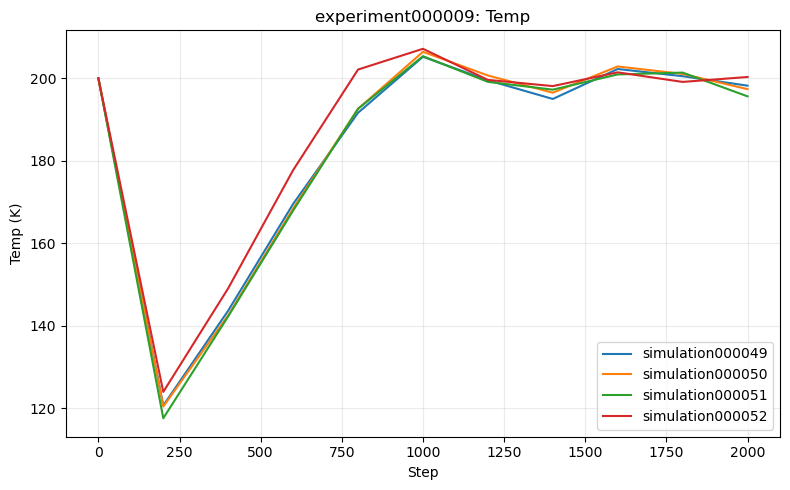

In [4]:
experiment.plot("Temp")
plt.show()

To plot a single simulation, provide its ID. You can also pass a list of simulation IDs.

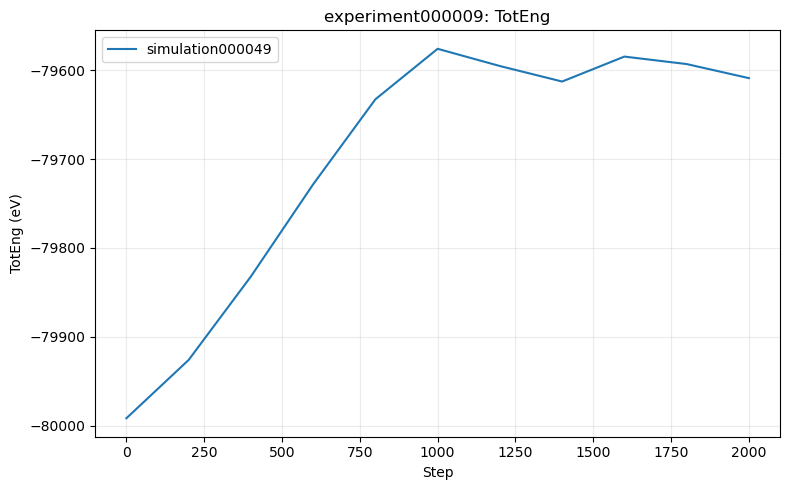

In [5]:
simulation_id = experiment.df["simulation_id"].iloc[0]
experiment.plot("TotEng", simulation_ids=simulation_id)
plt.show()

## Optional: pressure plot and DataFrame access

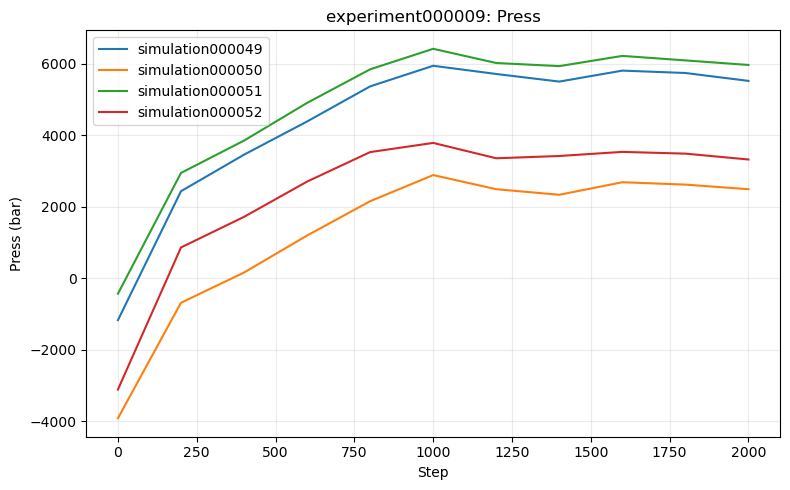

,simulation_id,Step,Temp,TotEng,Press
0,simulation000049,0,200.00000,-79991.335,-1168.2775
1,simulation000049,200,120.69190,-79925.828,2438.2032
2,simulation000049,400,143.68980,-79832.035,3460.5030
3,simulation000049,600,169.54304,-79728.446,4389.1295
4,simulation000049,800,191.63378,-79632.906,5370.9056


In [6]:
experiment.plot("Press")
plt.show()

# Example: access data for a single simulation
single_simulation_df = experiment.df.query("simulation_id == @simulation_id")
display(single_simulation_df.head())

Equilibrium lattice parameter (energy minimum): 3.00017 Å
Bulk modulus: 131.406 GPa
B0' = 4.280


<Axes: title={'center': 'experiment000010: Birch–Murnaghan EOS'}, xlabel='Volume per atom ($\\mathrm{\\AA}^3$)', ylabel='Mean total energy (eV/atom)'>

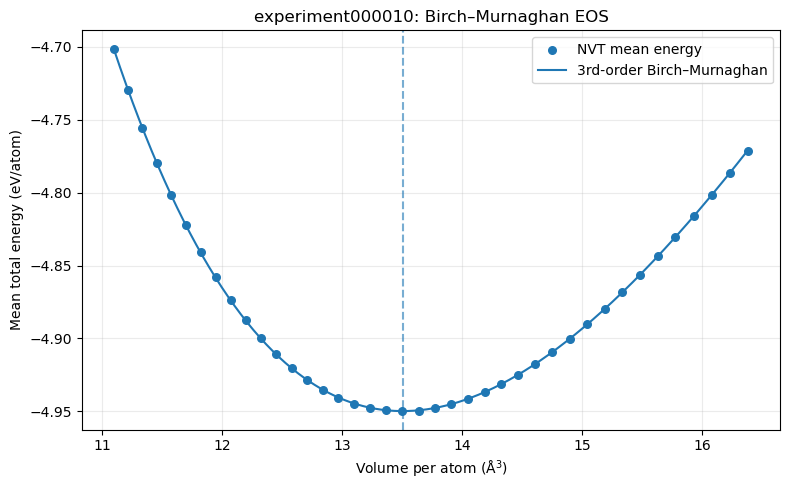

In [9]:
experiment = LammpsExperiment(
    "experiment000010",  # Replace with your experiment ID
    repo_root=REPO_ROOT
)

results = experiment.fit_birch_murnaghan(
    discard_fraction=0.5
)

experiment.plot_birch_murnaghan()